# Maps, flows and networks

Choropleths (per-capita rates!), tile maps, density maps; Sankey, chord and arc diagrams; force-directed networks and flowcharts. matplotlib maps draw the downloaded GeoJSON directly - no geopandas needed.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
import pandas as pd
import pychartist as pc
import plotly.io as pio
pio.renderers.default = "plotly_mimetype+notebook_connected"   # renders in JupyterLab/VS Code/Colab; plotly.js from CDN

In [2]:
g07 = pc.datasets.load('gapminder').query('year == 2007').merge(pc.datasets.load('world_gdp'),
                                                            left_on='country', right_on='COUNTRY')
us = pc.datasets.load('us_ag_exports')

In [3]:
pc.choropleth(g07, 'CODE', 'lifeExp', backend='plotly', title='Life expectancy, 2007')

<Chart kind='choropleth' backend='plotly' theme='pychartist'>

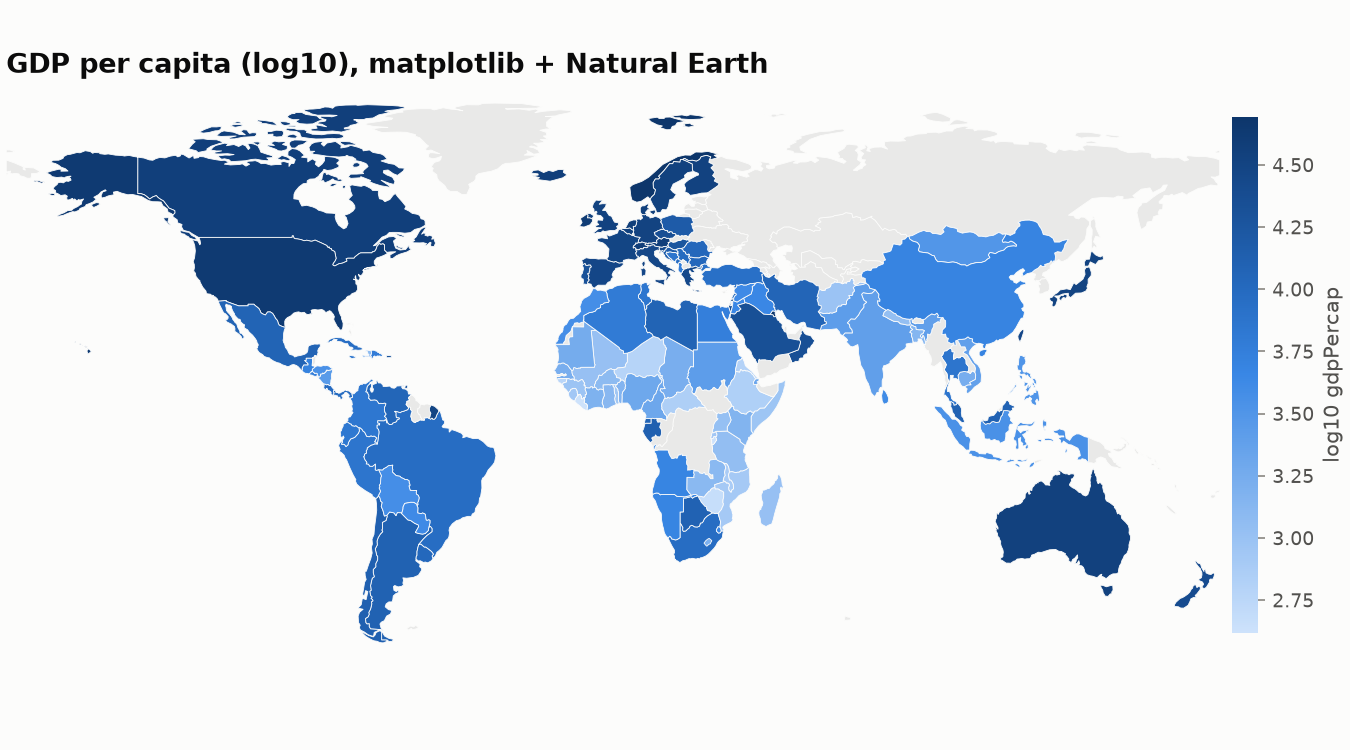

In [4]:
pc.choropleth(g07, 'CODE', 'gdpPercap', log=True, title='GDP per capita (log10), matplotlib + Natural Earth')

In [5]:
pc.choropleth(us, 'code', 'total exports', scope='usa', log=True, backend='plotly')

<Chart kind='choropleth' backend='plotly' theme='pychartist'>

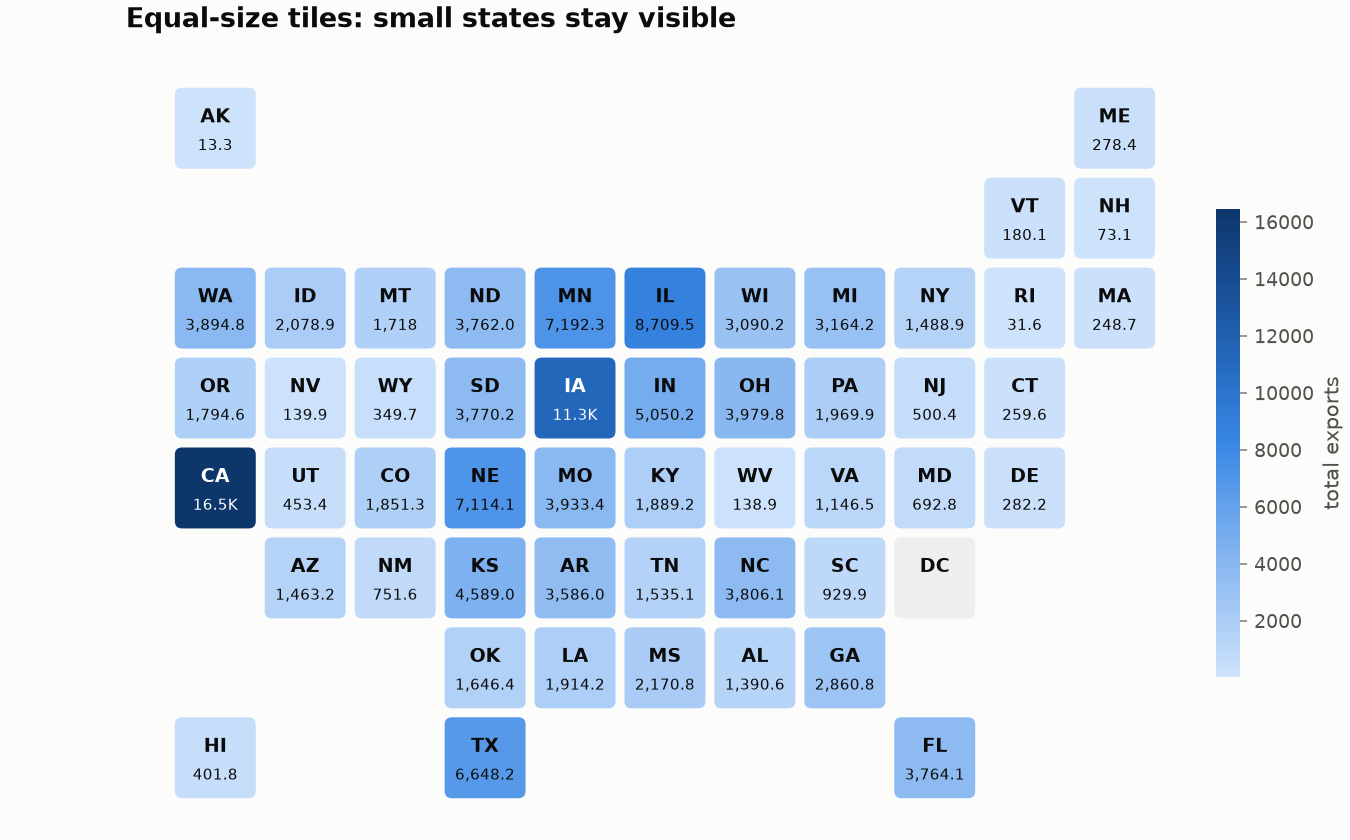

In [6]:
pc.tile_map(us, 'code', 'total exports', title='Equal-size tiles: small states stay visible')

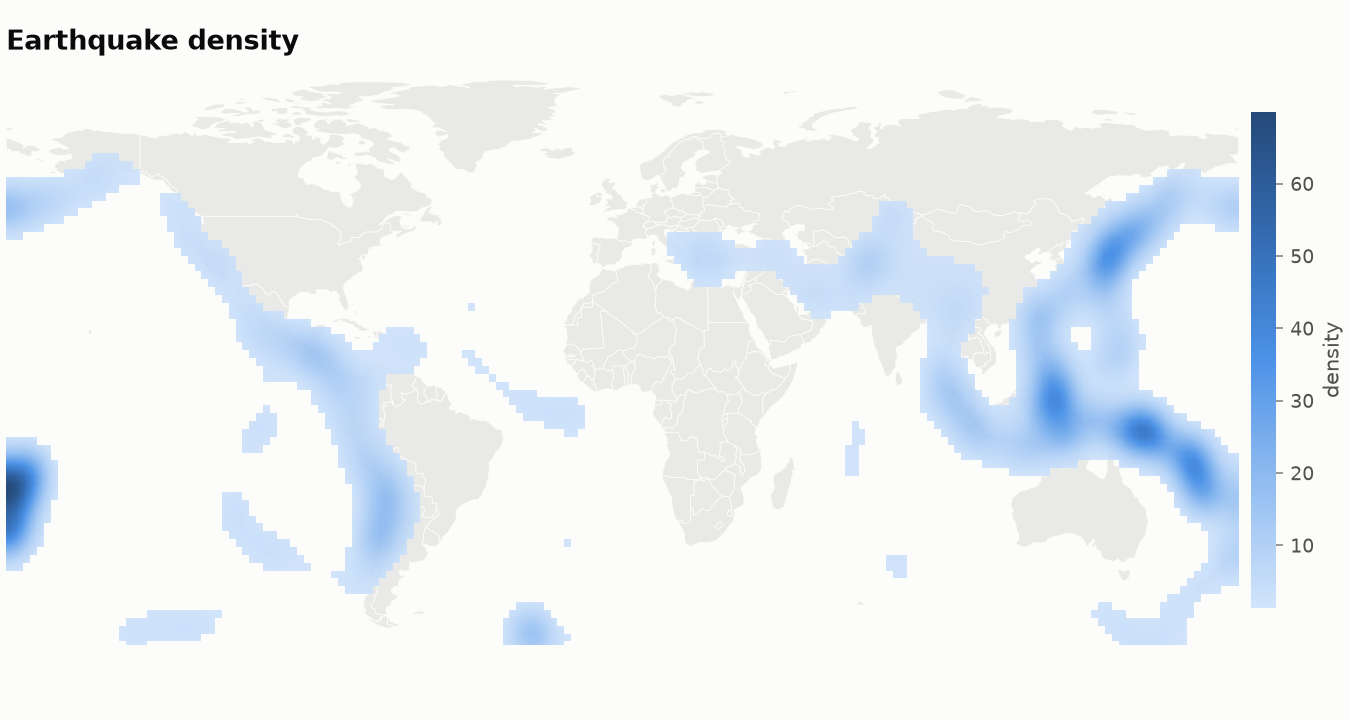

In [7]:
quakes = pc.datasets.load('earthquakes')
pc.geo_heatmap(quakes, 'Latitude', 'Longitude', basemap='outline', title='Earthquake density')

Interactive tile basemap (needs internet for map tiles):

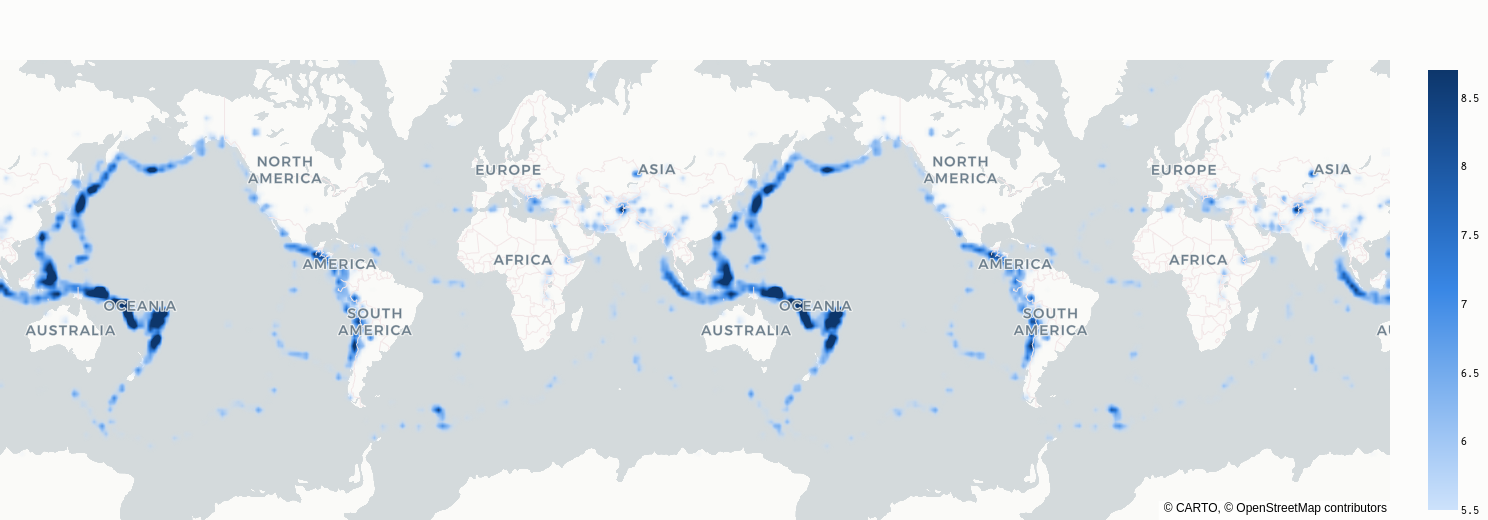

In [8]:
pc.geo_heatmap(quakes.sample(5000, random_state=0), 'Latitude', 'Longitude', 'Magnitude', radius=6,
               backend='plotly', zoom=0.4)

## Flows

In [9]:
pc.examples.demo('sankey', backend='plotly')

<Chart kind='sankey' backend='plotly' theme='pychartist'>

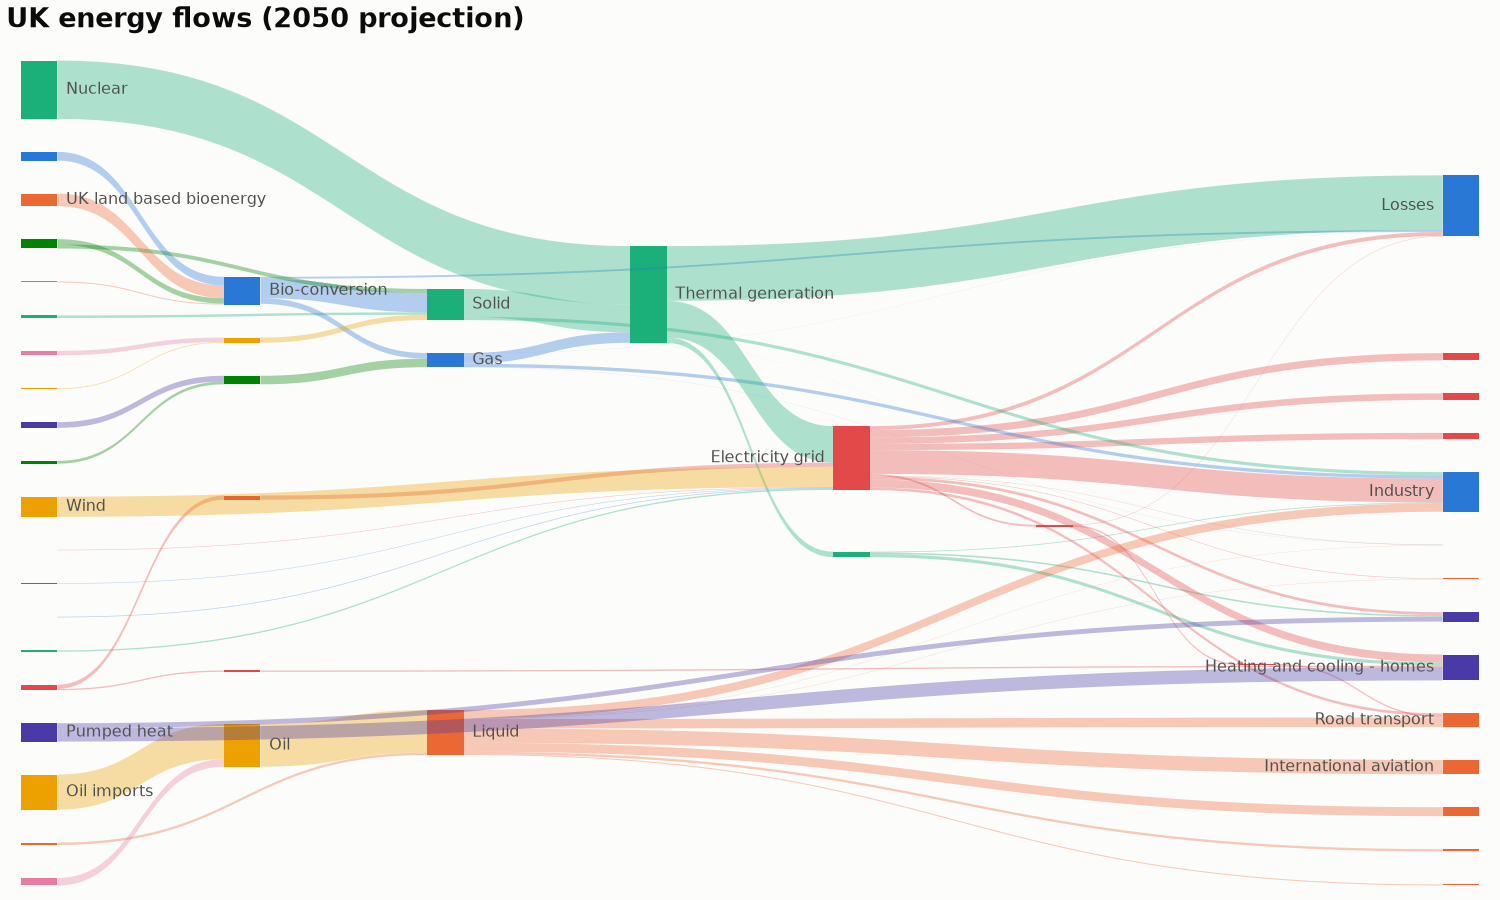

In [10]:
pc.examples.demo('sankey')

In [11]:
pc.examples.demo('chord', backend='plotly')

<Chart kind='chord' backend='plotly' theme='pychartist'>

## Networks

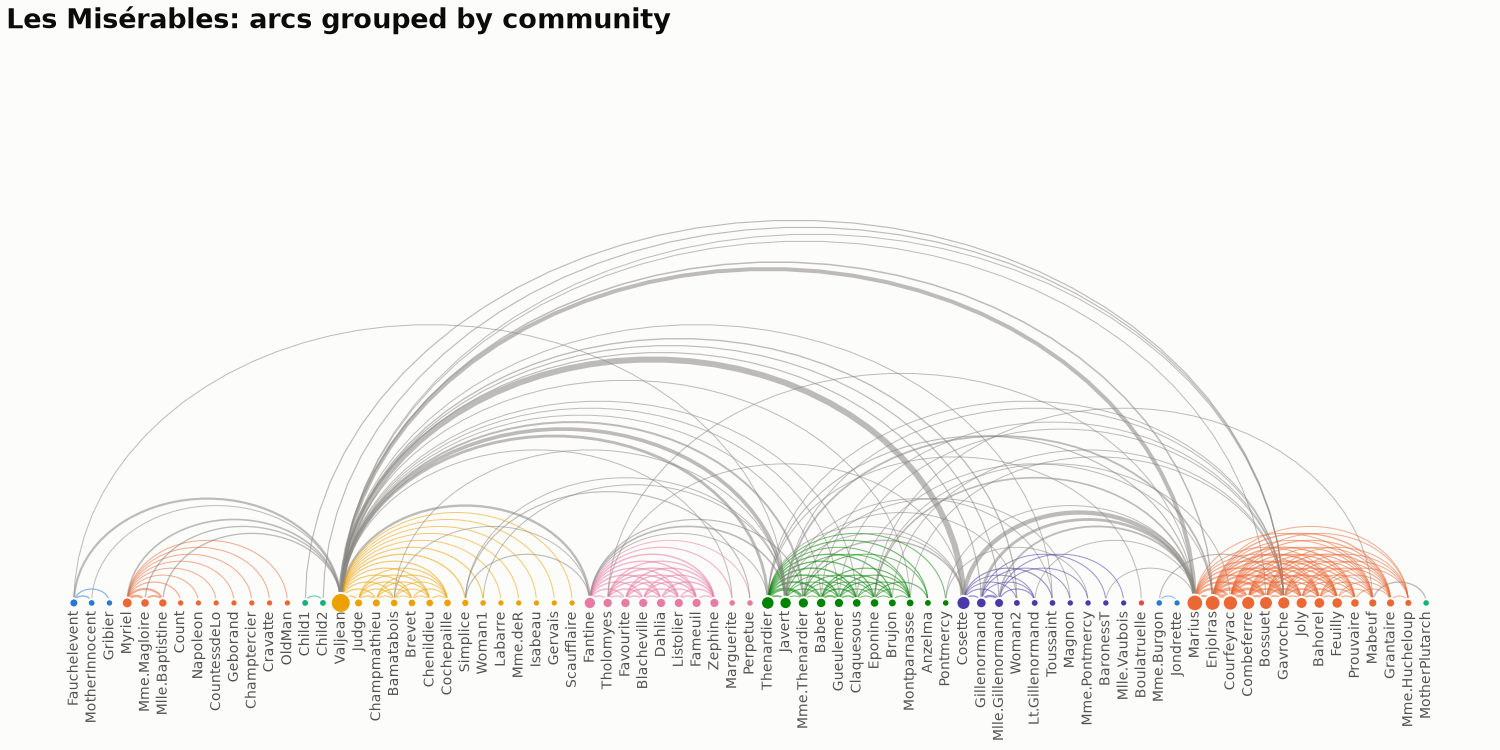

In [12]:
mis = pc.datasets.load('miserables')
pc.arc(mis, title='Les Misérables: arcs grouped by community')

In [13]:
pc.network(mis, backend='plotly', title='Drag to zoom; size = weighted degree')

<Chart kind='network' backend='plotly' theme='pychartist'>

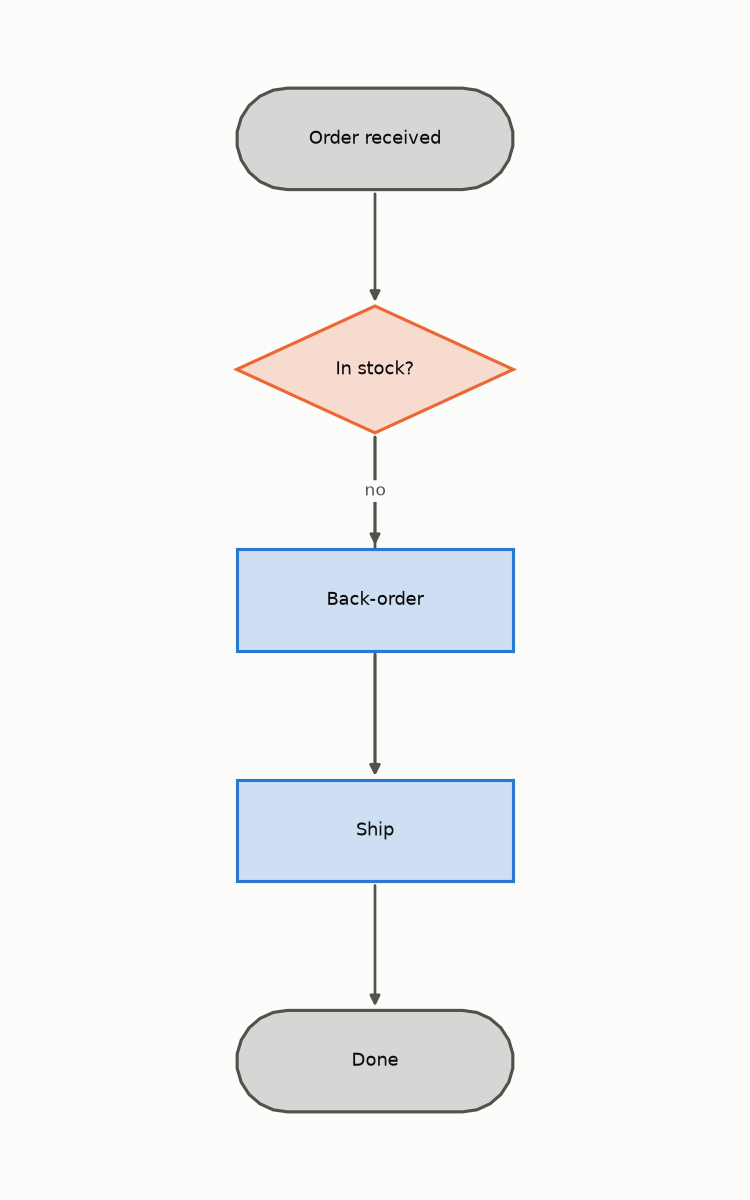

In [14]:
steps = pd.DataFrame({'id': ['s', 'q', 'a', 'b', 'e'], 'label': ['Order received', 'In stock?', 'Ship',
                      'Back-order', 'Done'], 'shape': ['terminal', 'decision', 'process', 'process', 'terminal']})
pc.flowchart(steps, [('s', 'q'), ('q', 'a', 'yes'), ('q', 'b', 'no'), ('b', 'a'), ('a', 'e')])